# Análise exploratória: CirCor DigiScope

Objetivo: perceber os dados antes de desenhar os modelos. Cada secção termina com a
**consequência para o desenho** do sistema, que é o que interessa justificar nos slides.

Os dados são lidos de `../circor-dataset`, ao lado do repositório (ou da variável de ambiente `CIRCOR_DIR`).
As secções 1-3 só precisam do `training_data.csv`; as restantes precisam das gravações.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.signal import welch

from murmur.data import CLASSES, WA_WEIGHTS, load_patients, load_recordings, load_wav, preprocess, recording_labels
from murmur.features import Frontend
from murmur.plots import CLASS_COLORS, INK_2, MUTED, SERIES, setup_style

%matplotlib inline
setup_style()
pd.set_option("display.width", 140)

DATA_DIR = Path(os.environ.get("CIRCOR_DIR", ROOT.parent / "circor-dataset"))
patients = load_patients(DATA_DIR)
recordings = load_recordings(DATA_DIR)
HAS_AUDIO = len(recordings) > 0
print(f"{len(patients)} patients, {len(recordings)} recordings available in {DATA_DIR}")

942 patients, 3163 recordings available in /Users/bernardosoeiro/faculdade/3ano/1semestre/ac2/circor-dataset


## 1. Labels ao nível do paciente e baselines triviais

,patients,percent,WA if always predicted
murmur,,,
Present,179,19.0,0.499
Unknown,68,7.2,0.114
Absent,695,73.8,0.387


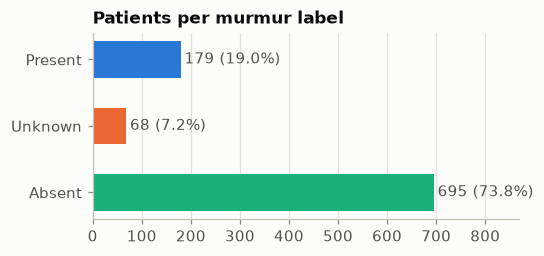

In [2]:
counts = patients["murmur"].value_counts().reindex(CLASSES)
summary = counts.to_frame("patients").assign(percent=(100 * counts / counts.sum()).round(1))
total = float((counts.to_numpy() * WA_WEIGHTS).sum())
summary["WA if always predicted"] = (WA_WEIGHTS * counts.to_numpy() / total).round(3)
display(summary)

fig, ax = plt.subplots(figsize=(5, 2.2))
ax.barh(CLASSES[::-1], counts[CLASSES[::-1]], height=0.55, color=[CLASS_COLORS[c] for c in CLASSES[::-1]])
for i, c in enumerate(CLASSES[::-1]):
    ax.text(counts[c] + 8, i, f"{counts[c]} ({summary.loc[c, 'percent']}%)", va="center", color=INK_2)
ax.set_title("Patients per murmur label")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, counts.max() * 1.25)
plt.show()

**Consequência.** As classes estão desequilibradas (≈74% Absent, 19% Present, 7% Unknown), mas a
métrica pesa Present 5× e Unknown 3×. Dizer sempre *Present* dá WA ≈ 0.50, mais do que dizer
sempre *Absent* (≈ 0.39). Qualquer modelo tem de ficar claramente acima de 0.50. A perda de treino
usa os pesos da métrica (5, 3, 1). Pela regra de Bayes, isto alinha o argmax da rede com a
decisão que maximiza a WA (ver `murmur/evaluation.py`).

## 2. A mesma criança nas duas campanhas

In [3]:
linked = patients[patients["additional_id"].notna()]
pairs = linked.merge(patients, left_on=linked["additional_id"].astype(int), right_on="patient_id",
                     suffixes=("", "_other"))
pairs = pairs[pairs["patient_id"] < pairs["patient_id_other"]]
print(f"{len(linked)} patient ids = {len(pairs)} children recorded in both campaigns (CC2014 and CC2015)")
print(f"label agreement between the two visits: {(pairs['murmur'] == pairs['murmur_other']).mean():.1%}")
pd.crosstab(pairs["murmur"], pairs["murmur_other"], rownames=["visit A"], colnames=["visit B"])

140 patient ids = 70 children recorded in both campaigns (CC2014 and CC2015)
label agreement between the two visits: 78.6%


visit B,Absent,Present,Unknown
visit A,,,
Absent,36,3,4
Present,1,18,3
Unknown,2,2,1


**Consequência.** Dividir só por `Patient ID` poria a mesma criança em treino e em teste
(fuga de informação, resultados otimistas). Os splits são agrupados por **sujeito**
(`make_splits` em `murmur/data.py`). Além disso, a concordância entre as duas visitas não é total: há ruído nas
labels, sobretudo à volta de *Unknown*, e isto limita a WA atingível.

## 3. Campanha, idade e localizações do sopro

In [4]:
display(pd.crosstab(patients["campaign"], patients["murmur"], normalize="index").round(3))
display(pd.crosstab(patients["age"].fillna("(missing)"), patients["murmur"], normalize="index").round(3))

present = patients[patients["murmur"] == "Present"].copy()
present["n_recorded"] = present["recording_locations"].str.split("+").map(lambda l: len(set(l)))
present["n_murmur"] = present["murmur_locations"].fillna("").str.split("+").map(lambda l: len(set(l) - {""}))
print(f"Present patients: murmur heard at ALL recorded locations in {(present['n_murmur'] >= present['n_recorded']).mean():.0%}")
display(present["murmur_locations"].value_counts().head(10).to_frame())
display(present["most_audible_location"].value_counts().to_frame())

murmur,Absent,Present,Unknown
campaign,,,
CC2014,0.784,0.164,0.052
CC2015,0.706,0.208,0.086


murmur,Absent,Present,Unknown
age,,,
(missing),0.905,0.068,0.027
Adolescent,0.736,0.222,0.042
Child,0.745,0.199,0.056
Infant,0.603,0.198,0.198
Neonate,0.667,0.167,0.167


Present patients: murmur heard at ALL recorded locations in 62%

,count
murmur_locations,
AV+MV+PV+TV,70
AV+MV,19
MV+PV+TV,17
MV,16
TV,10
MV+TV,9
PV+TV,8
AV+PV+TV,6
AV+PV,6


,count
most_audible_location,
PV,62
TV,56
MV,42
AV,19


**Observações.** Os bebés (*Infant*) têm ~20% de *Unknown*, contra ~5% nas crianças: são gravações mais
difíceis (choro, movimento, frequência cardíaca alta). A campanha CC2015 tem mais *Present* e *Unknown*
do que a CC2014, e por isso os splits também são estratificados por campanha.

**Consequência.** Em 38% dos pacientes *Present* (68 de 179) o sopro **não** se ouve em todos os focos
gravados. Por isso:
1. ao nível da gravação usamos `label_mode=location`: uma gravação de um paciente Present só é
   Present se o sopro foi ouvido nesse foco (campo `Murmur locations`), senão é Absent;
2. ao agregar gravações → paciente, a pontuação *Present* é o **máximo** sobre os focos
   (basta um foco com sopro). Isto é comparado com a média em validação cruzada.

## 4. Gravações por paciente e labels ao nível da gravação

In [5]:
if HAS_AUDIO:
    print("recordings per patient:")
    display(recordings.groupby("patient_id").size().value_counts().sort_index().to_frame("patients"))
    display(recordings["location"].value_counts().to_frame())
    recordings["label_location"] = [CLASSES[i] for i in recording_labels(recordings, patients, "location")]
    recordings["label_patient"] = [CLASSES[i] for i in recording_labels(recordings, patients, "patient")]
    display(pd.crosstab(recordings["label_patient"], recordings["label_location"],
                        rownames=["label = patient"], colnames=["label = location"]))
else:
    print("no recordings: download the dataset first (bash scripts/download_data.sh)")

recordings per patient:


,patients
1,62
2,156
3,123
4,588
5,10
6,3


,count
location,
MV,861
AV,800
PV,766
TV,732
Phc,4


label = location,Absent,Present,Unknown
label = patient,,,
Absent,2391,0,0
Present,117,499,0
Unknown,0,0,156


## 5. Duração das gravações

,count,mean,std,min,25%,50%,75%,max
label_location,,,,,,,,
Absent,2508.0,22.9,7.1,5.2,19.1,21.6,29.5,58.8
Present,499.0,22.7,8.1,6.4,18.9,21.2,28.9,64.5
Unknown,156.0,22.4,7.0,7.6,19.2,21.1,27.2,43.9


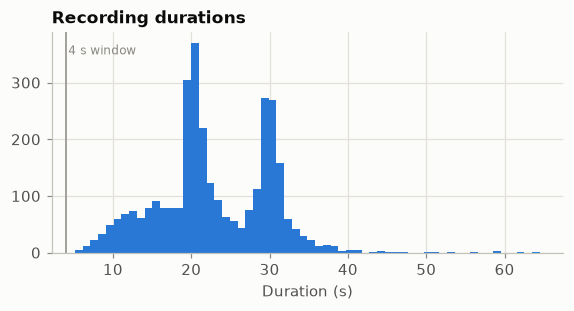

In [6]:
def duration_s(wav_path):
    _, _, fs, n = Path(wav_path).with_suffix(".hea").read_text().split()[:4]
    return int(n) / int(fs)

if HAS_AUDIO:
    recordings["duration_s"] = recordings["wav_path"].map(duration_s)
    display(recordings.groupby("label_location")["duration_s"].describe().round(1))
    fig, ax = plt.subplots(figsize=(6, 2.6))
    ax.hist(recordings["duration_s"], bins=60, color=SERIES[0])
    ax.axvline(4, color=MUTED, lw=1)
    ax.text(4.3, ax.get_ylim()[1] * 0.9, "4 s window", color=MUTED, fontsize=8)
    ax.set_xlabel("Duration (s)")
    ax.set_title("Recording durations")
    plt.show()

**Consequência.** As durações variam muito (≈5–80 s), por isso as redes recebem **janelas fixas de 4 s**
(várias batidas, mesmo a 60 bpm). Em treino, cada gravação dá 4 recortes aleatórios por época
(aumento de dados, e as gravações longas não dominam). Em avaliação, as janelas deslizam com 50% de
sobreposição e as probabilidades são somadas em média por gravação.

## 6. Exemplos: sinal, segmentação S1/sístole/S2/diástole e log-mel

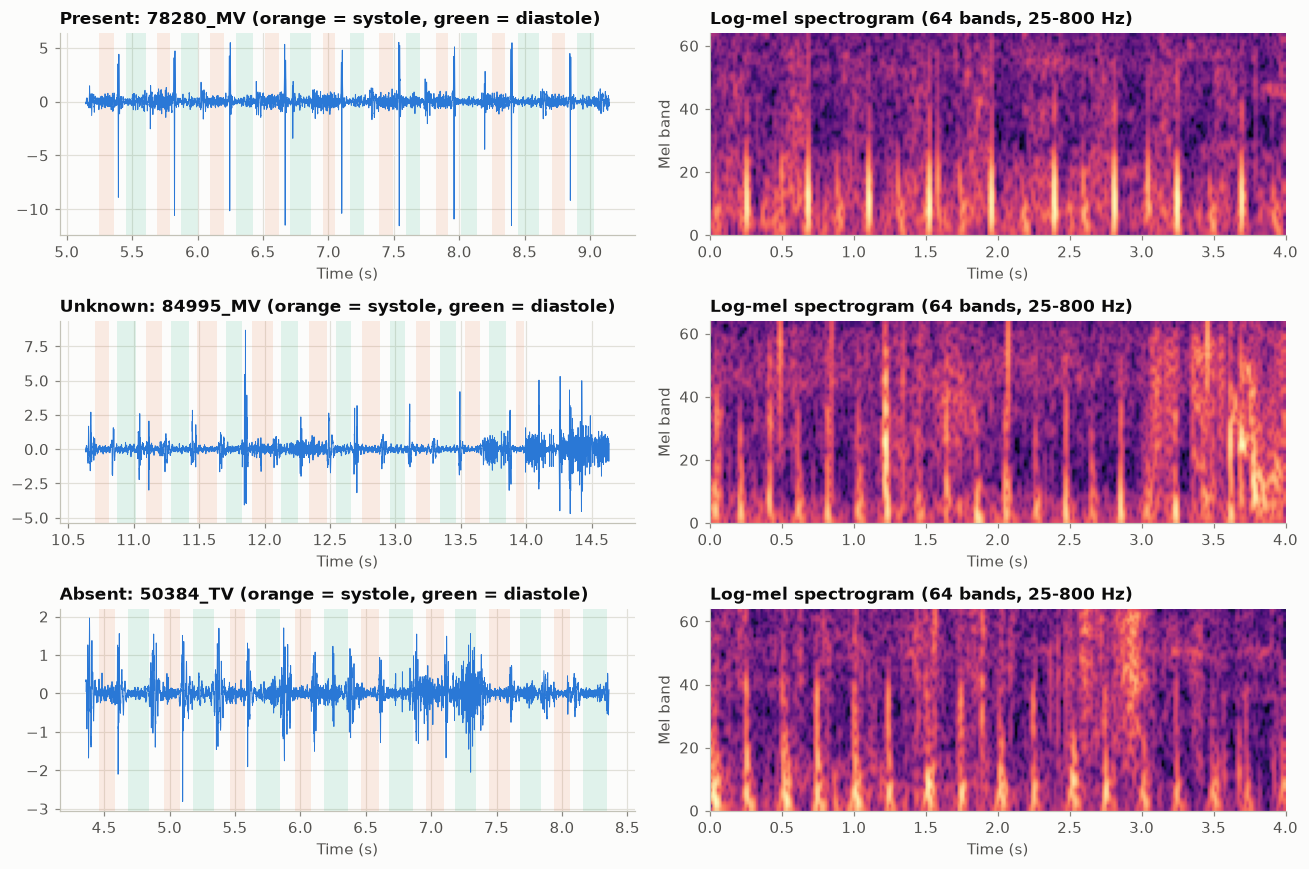

In [7]:
STATE_COLORS = {2: SERIES[1], 4: SERIES[2]}  # systole, diastole
frontend = Frontend(2000).eval()

def show_example(ax_wave, ax_spec, rec, title, seconds=4.0):
    x, fs = load_wav(rec["wav_path"])
    y = preprocess(x, fs)
    tsv = Path(rec["wav_path"]).with_suffix(".tsv")
    seg = pd.read_csv(tsv, sep="\t", header=None, names=["start", "end", "state"]) if tsv.exists() else None
    t0 = seg.loc[seg["state"] == 1, "start"].iloc[min(2, (seg["state"] == 1).sum() - 1)] if seg is not None and (seg["state"] == 1).any() else 0.0
    sl = slice(int(t0 * 2000), int((t0 + seconds) * 2000))
    t = np.arange(sl.start, sl.start + len(y[sl])) / 2000
    ax_wave.plot(t, y[sl], lw=0.6, color=SERIES[0])
    if seg is not None:
        for _, s in seg[(seg["end"] > t0) & (seg["start"] < t0 + seconds)].iterrows():
            if s["state"] in STATE_COLORS:
                ax_wave.axvspan(max(s["start"], t0), min(s["end"], t0 + seconds), color=STATE_COLORS[s["state"]], alpha=0.12, lw=0)
    ax_wave.set_title(f"{title} (orange = systole, green = diastole)")
    ax_wave.set_xlabel("Time (s)")
    S = frontend(torch.tensor(y[sl])[None])[0].numpy()
    ax_spec.imshow(S, origin="lower", aspect="auto", cmap="magma", extent=[0, seconds, 0, S.shape[0]])
    ax_spec.grid(False)
    ax_spec.set_title("Log-mel spectrogram (64 bands, 25-800 Hz)")
    ax_spec.set_xlabel("Time (s)")
    ax_spec.set_ylabel("Mel band")

if HAS_AUDIO:
    pat = patients.set_index("patient_id")
    examples = []
    for label in CLASSES:
        cand = recordings[recordings["label_location"] == label]
        if label == "Present":  # a recording at the most audible location
            best = cand[[loc == pat.at[p, "most_audible_location"] for p, loc in zip(cand["patient_id"], cand["location"])]]
            cand = best if len(best) else cand
        examples.append((label, cand.sample(1, random_state=1).iloc[0]))
    fig, axes = plt.subplots(3, 2, figsize=(12, 8))
    for (label, rec), (aw, asp) in zip(examples, axes):
        show_example(aw, asp, rec, f"{label}: {rec['rec_id']}")
    fig.tight_layout()
    plt.show()

**O que procurar.** Num *Present*, o espaço entre S1 e S2 (sístole) tem energia contínua em
várias bandas. Num *Absent*, S1 e S2 são impulsos curtos com silêncio entre eles. Num *Unknown*,
espera-se ruído que esconde o ritmo. Um padrão tempo-frequência local e repetido a cada batida
é exatamente o que uma CNN 2D deteta bem. A sequência de batidas (ritmo, sístole vs diástole)
é o que motiva o RNN.

## 7. Conteúdo espectral por classe

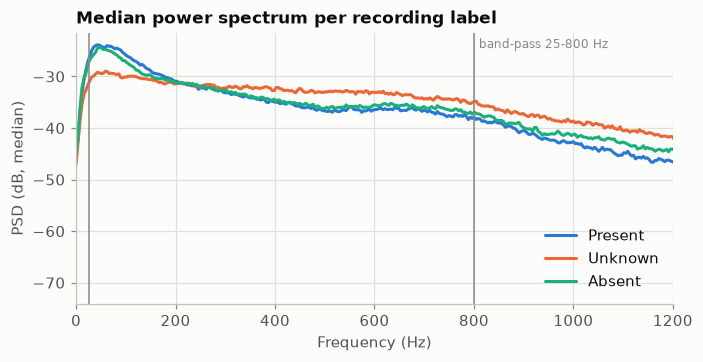

In [8]:
if HAS_AUDIO:
    rng = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(7, 3.2))
    for label in CLASSES:
        sample = recordings[recordings["label_location"] == label].sample(min(150, (recordings["label_location"] == label).sum()), random_state=0)
        psds = []
        for wav in sample["wav_path"]:
            x, fs = load_wav(wav)
            x = (x - x.mean()) / (x.std() + 1e-8)
            f, p = welch(x, fs=fs, nperseg=1024)
            psds.append(10 * np.log10(p + 1e-12))
        ax.plot(f, np.median(psds, axis=0), color=CLASS_COLORS[label], label=label)
    for edge in (25, 800):
        ax.axvline(edge, color=MUTED, lw=1)
    ax.text(810, ax.get_ylim()[1] - 3, "band-pass 25-800 Hz", color=MUTED, fontsize=8)
    ax.set_xlim(0, 1200)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (dB, median)")
    ax.set_title("Median power spectrum per recording label")
    ax.legend()
    plt.show()

**Resultado.** O espectro mediano de *Present* e *Absent* é quase igual: estatísticas espectrais **globais**
quase não separam as classes. A informação do sopro está **quando** a energia aparece (na sístole,
entre S1 e S2), e não em quanta energia há no total. Isto é um argumento a favor de representações
tempo-frequência (CNN) e sequenciais (RNN), em vez de um MLP sobre médias globais. Os *Unknown*
têm um espectro mais plano (menos energia abaixo de 150 Hz, mais acima de ~400 Hz), o que é
compatível com ruído. Acima de 800 Hz a potência continua a cair (mais de 10 dB abaixo do pico a
50–100 Hz), por isso o passa-banda 25–800 Hz e a reamostragem para 2 kHz perdem pouco.

## 8. Características dos sopros (pacientes Present)

In [9]:
cols = ["systolic_murmur_timing", "systolic_murmur_grading", "systolic_murmur_pitch", "systolic_murmur_quality"]
for c in cols:
    display(present[c].value_counts(dropna=False).to_frame())
print(f"diastolic murmurs: {present['diastolic_murmur_timing'].notna().sum()} of {len(present)} Present patients")

,count
systolic_murmur_timing,
Holosystolic,101
Early-systolic,59
Mid-systolic,17
NaN,1
Late-systolic,1


,count
systolic_murmur_grading,
I/VI,104
III/VI,46
II/VI,28
NaN,1


,count
systolic_murmur_pitch,
Low,87
Medium,49
High,42
NaN,1


,count
systolic_murmur_quality,
Harsh,96
Blowing,78
Musical,4
NaN,1


diastolic murmurs: 5 of 179 Present patients


**Consequência.** 178 de 179 sopros são sistólicos (só 5 pacientes têm também sopro diastólico) e 58%
são de grau I/VI, o mais fraco. Quase metade tem *pitch* baixo, ou seja, sobrepõe-se em frequência a
S1/S2. Os sopros fracos e graves são os casos difíceis. A informação temporal (o sopro aparece
*entre* S1 e S2) ajuda a separá-los, o que favorece representações tempo-frequência (CNN) e
sequenciais (RNN) em vez de estatísticas globais.

## 9. Verificação dos splits

In [10]:
splits_path = ROOT / "configs" / "splits.csv"
if splits_path.exists():
    splits = pd.read_csv(splits_path)
    display(pd.crosstab(splits["subset"], splits["murmur"], normalize="index").round(3))
    display(pd.crosstab(splits.loc[splits["subset"] == "dev", "fold"], splits["murmur"], margins=True))
    print("subjects in more than one subset:", splits.groupby("subject_id")["subset"].nunique().gt(1).sum())

murmur,Absent,Present,Unknown
subset,,,
dev,0.738,0.19,0.072
test,0.735,0.19,0.074


murmur,Absent,Present,Unknown,All
fold,,,,
0,111,29,11,151
1,112,28,11,151
2,111,29,11,151
3,111,28,11,150
4,111,29,10,150
All,556,143,54,753


subjects in more than one subset: 0


## Resumo das decisões de desenho

| Observação | Decisão |
|---|---|
| Classes desequilibradas, métrica pesa P×5 e U×3 | CE com pesos (5, 3, 1) + regra de decisão validada em CV |
| 70 crianças com 2 IDs | Splits agrupados por sujeito, estratificados por label × campanha |
| Sopro só em alguns focos | Labels por gravação a partir de `Murmur locations`; agregação *max* para Present |
| Durações 5–80 s | Janelas de 4 s (recortes aleatórios em treino, deslizantes em avaliação) |
| Energia útil < 800 Hz | Passa-banda 25–800 Hz, reamostragem para 2 kHz, log-mel / MFCC |